# 02. Modelo de risco de atraso

**Objetivo:** estimar, para cada cliente da carteira, a probabilidade de atrasar mais de 15 dias no período de previsão, e usar essa probabilidade para ordenar a cobrança.

**Como o modelo é avaliado:** a base é desbalanceada (1,7% de clientes em risco), então a acurácia não serve. O critério principal é a capacidade de colocar os clientes de risco no topo da lista: quanto dos casos de risco, e do valor deles, fica nos 10% e 20% de clientes com maior score.

**Variáveis:** o modelo usa só o comportamento de pagamento até a data de corte. Os dados cadastrais são do pedido atual, posterior ao corte; por isso ficam de fora (ver `docs/decisoes.md`, item 19). A seção 8.1 mede quanto desempenho essa escolha custa.

**Etapas:** preparação das variáveis, divisão entre treino e teste, comparação de três abordagens e de dois conjuntos de variáveis, avaliação no teste, leitura do que o modelo aprendeu, teste com o critério de 30 dias, teste com os dados cadastrais, calibração das probabilidades e gravação dos scores no banco.

## 1. Preparação

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sqlalchemy.types import DECIMAL, Float, Integer, SmallInteger
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").exists())
sys.path.append(str(ROOT / "src"))

from db import write_table
from modeling import (BEHAVIOR_FEATURES, CATEGORICAL_FEATURES, NUMERIC_FEATURES, PAYMENT_HISTORY_FEATURES,
                      PROFILE_NUMERIC, capture_at_top, gains_curve, load_client_base, prepare_features)

FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42  # semente fixa: os resultados saem iguais a cada execução
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)

## 2. Dados e variáveis

As variáveis são montadas em `src/modeling.py`, em dois grupos de comportamento, ambos com informação conhecida no dia do corte:
- **histórico de pagamento:** quantas parcelas o cliente pagou com atraso, o maior atraso, o atraso recente, pagamentos em partes;
- **carteira no corte:** parcelas vencidas e ainda em aberto naquele dia, contratos ativos, saldo a vencer (calculado pelas condições dos contratos), tempo desde o último contrato e contratos feitos no último ano.

Os dados cadastrais também são preparados, para a comparação da seção 8.1. Ajustes aplicados:
- valores monetários em logaritmo, para clientes muito grandes não dominarem o modelo;
- atrasos limitados a 365 dias, porque parcelas em aberto há anos geram valores extremos;
- tipos de renda raros agrupados em "Other" e clientes sem cadastro com categoria própria.

**Valor a receber:** o valor previsto para vencer no período, calculado pelas condições dos contratos no dia do corte (`scheduled_window_amount`). É o valor que a empresa conheceria naquele dia; ele não entra como variável, é usado para medir o valor em risco.

In [2]:
df = load_client_base()
X = prepare_features(df)
y = df["target_late_15"].astype(int)
value = df["scheduled_window_amount"]  # valor previsto no corte (ver docs/decisoes.md, item 22)

print(f"{len(X):,} clientes, {len(BEHAVIOR_FEATURES)} variáveis de comportamento no modelo, {y.mean():.2%} em risco")
X.head()

156,333 clientes, 17 variáveis de comportamento no modelo, 1.68% em risco


,hist_contracts,hist_installments,log_hist_amount_due,hist_pct_late,hist_pct_late_15,hist_max_days_late,hist_avg_days_late,hist_pct_split_payment,recent_installments,recent_pct_late,...,days_since_last_contract,contracts_last_year,has_profile,log_income,age_years,years_employed,no_current_job,region_rating,income_type,education_level
0,1.000,7.000,11.078,0.000,0.000,-22.000,-25.290,0.000,6.000,0.000,...,241.000,1.000,1.000,12.219,25.000,1.700,0.000,2.000,Working,Secondary / secondary special
1,4.000,50.000,13.301,0.320,0.000,12.000,-2.040,0.060,6.000,0.000,...,9.000,1.000,1.000,11.708,54.000,8.300,0.000,2.000,Working,Secondary / secondary special
2,3.000,24.000,13.565,0.042,0.042,365.000,43.790,0.042,5.000,0.000,...,5.000,2.000,1.000,11.503,46.000,4.300,0.000,2.000,State servant,Secondary / secondary special
3,4.000,24.000,12.488,0.000,0.000,-1.000,-7.670,0.000,2.000,0.000,...,84.000,1.000,1.000,12.049,37.000,8.600,0.000,2.000,Commercial associate,Higher education
4,2.000,39.000,13.836,0.410,0.026,365.000,23.820,0.231,6.000,1.000,...,824.000,0.000,1.000,11.631,55.000,NaN,1.000,2.000,Pensioner,Secondary / secondary special


## 3. Divisão entre treino e teste

70% dos clientes para treinar e 30% para testar. O teste fica guardado até o fim e só é usado para a avaliação final, como uma prova que o modelo nunca viu. A divisão é estratificada: a proporção de clientes em risco é a mesma nos dois grupos.

In [3]:
X_train, X_test, y_train, y_test, value_train, value_test = train_test_split(
    X, y, value, test_size=0.30, stratify=y, random_state=SEED
)
print(f"Treino: {len(X_train):,} clientes ({y_train.mean():.2%} em risco)")
print(f"Teste:  {len(X_test):,} clientes ({y_test.mean():.2%} em risco)")

Treino: 109,433 clientes (1.68% em risco)
Teste:  46,900 clientes (1.68% em risco)


## 4. As abordagens

1. **Regra simples (referência):** ordena os clientes pelo % de parcelas atrasadas nos 6 meses antes do corte, o melhor sinal da análise exploratória. É o que uma equipe de cobrança faria sem modelo. Um modelo só se justifica se superar essa regra.
2. **Regressão logística:** modelo linear e interpretável.
3. **Gradient boosting:** combina muitas árvores de decisão e captura relações não lineares entre as variáveis.

Os dois modelos são testados com dois conjuntos de variáveis: só o **histórico de pagamento** e o histórico **mais a carteira no corte**. Assim dá para medir quanto as variáveis de carteira acrescentam.

Todos usam o mesmo tipo de pré-processamento: campos vazios preenchidos com a mediana (com uma coluna indicando que estava vazio) e variáveis padronizadas. O **peso de classe** (`class_weight="balanced"`) faz cada cliente em risco valer mais no treino, para o modelo não ignorar os poucos casos.

In [4]:
def rule_score(X):
    """Regra de referência: % de atraso recente; desempata pelo % de atraso no histórico."""
    return X["recent_pct_late"].fillna(0) + X["hist_pct_late"] / 1000


def make_preprocess(numeric, categorical=()):
    """Preenche vazios com a mediana, padroniza números e transforma categorias em colunas 0/1."""
    steps = [("num", Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ]), list(numeric))]
    if categorical:
        steps.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(categorical)))
    return ColumnTransformer(steps)


feature_sets = {
    "histórico": PAYMENT_HISTORY_FEATURES,
    "histórico + carteira": BEHAVIOR_FEATURES,
}
estimators = {
    "Regressão logística": LogisticRegression(class_weight="balanced", max_iter=2000),
    "Gradient boosting": HistGradientBoostingClassifier(
        class_weight="balanced", learning_rate=0.05, max_iter=300, random_state=SEED),
}

# Cada combinação recebe o próprio pré-processamento: se dividissem o mesmo objeto,
# treinar uma reajustaria o pré-processamento da outra.
models, model_features = {}, {}
for est_name, estimator in estimators.items():
    for set_name, features in feature_sets.items():
        name = f"{est_name} ({set_name})"
        models[name] = Pipeline([("prep", make_preprocess(features)), ("model", clone(estimator))])
        model_features[name] = features

## 5. Comparação por validação cruzada

Antes de olhar o teste, as combinações de modelo e variáveis são comparadas só dentro do treino: ele é dividido em 5 partes, e cada modelo é treinado 5 vezes, sempre avaliado na parte que ficou de fora. A combinação com maior precisão média (AP) é a escolhida, sem usar o teste.

Métricas:
- **AUC:** a chance de um cliente em risco receber score maior que um cliente sem risco (0,5 é sorteio, 1,0 é perfeito);
- **Precisão média (AP):** resume a qualidade do topo da lista; para referência, um score aleatório teria AP igual à taxa de risco, cerca de 0,017.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=["roc_auc", "average_precision"])
    cv_rows.append({
        "modelo": name,
        "AUC": scores["test_roc_auc"].mean(),
        "AP": scores["test_average_precision"].mean(),
    })

rule_train = rule_score(X_train)
cv_rows.append({"modelo": "Regra simples", "AUC": roc_auc_score(y_train, rule_train),
                "AP": average_precision_score(y_train, rule_train)})

cv_table = pd.DataFrame(cv_rows).set_index("modelo")
best_name = cv_table.drop("Regra simples")["AP"].idxmax()
print(f"Modelo escolhido pela validação cruzada: {best_name}")
cv_table

Modelo escolhido pela validação cruzada: Gradient boosting (histórico + carteira)


,AUC,AP
modelo,,
Regressão logística (histórico),0.755,0.110
Regressão logística (histórico + carteira),0.764,0.124
Gradient boosting (histórico),0.755,0.109
Gradient boosting (histórico + carteira),0.766,0.134
Regra simples,0.724,0.066


## 6. Avaliação no teste

Todas as combinações são treinadas no treino inteiro e avaliadas no teste, que só mede o resultado: a escolha já foi feita na seção 5. Além de AUC e AP, a tabela mostra a pergunta de negócio: se a cobrança contatar só os 10% ou 20% de clientes com maior score, quanto dos casos de risco e do valor em risco ela alcança.

In [6]:
test_scores = {"Regra simples": rule_score(X_test).to_numpy()}
for name, model in models.items():
    model.fit(X_train, y_train)
    test_scores[name] = model.predict_proba(X_test)[:, 1]

rows = []
for name, score in test_scores.items():
    cases_10, value_10 = capture_at_top(y_test, score, value_test, 0.10)
    cases_20, value_20 = capture_at_top(y_test, score, value_test, 0.20)
    rows.append({
        "modelo": name,
        "AUC": roc_auc_score(y_test, score),
        "AP": average_precision_score(y_test, score),
        "casos no top 10%": cases_10,
        "valor no top 10%": value_10,
        "casos no top 20%": cases_20,
        "valor no top 20%": value_20,
    })
test_table = pd.DataFrame(rows).set_index("modelo")
test_table

,AUC,AP,casos no top 10%,valor no top 10%,casos no top 20%,valor no top 20%
modelo,,,,,,
Regra simples,0.714,0.062,0.385,0.369,0.539,0.562
Regressão logística (histórico),0.737,0.093,0.433,0.399,0.556,0.541
Regressão logística (histórico + carteira),0.750,0.107,0.449,0.454,0.575,0.598
Gradient boosting (histórico),0.724,0.099,0.433,0.412,0.560,0.560
Gradient boosting (histórico + carteira),0.738,0.118,0.447,0.462,0.561,0.568


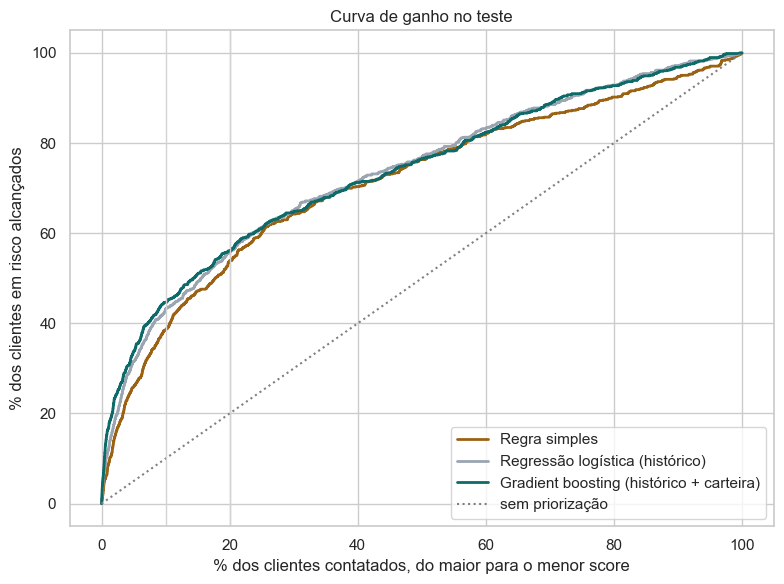

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
to_plot = {"Regra simples": "#9a6212",
           max([n for n in test_scores if "(histórico)" in n], key=lambda n: cv_table.loc[n, "AP"]): "#9aa5b1",
           best_name: "#0d6a68"}
for name, color in to_plot.items():
    x_curve, y_curve = gains_curve(y_test, test_scores[name])
    ax.plot(x_curve * 100, y_curve * 100, label=name, color=color, linewidth=2)
ax.plot([0, 100], [0, 100], color="grey", linestyle=":", label="sem priorização")
for share in (10, 20):
    ax.axvline(share, color="lightgrey", linewidth=1)
ax.set_xlabel("% dos clientes contatados, do maior para o menor score")
ax.set_ylabel("% dos clientes em risco alcançados")
ax.set_title("Curva de ganho no teste")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "02_curva_de_ganho.png", dpi=150)
plt.show()

## 7. O que o modelo aprendeu

Importância por permutação: embaralha uma variável de cada vez no teste e mede quanto a qualidade do topo da lista (AP) piora. Quanto maior a queda, mais o modelo depende daquela variável.

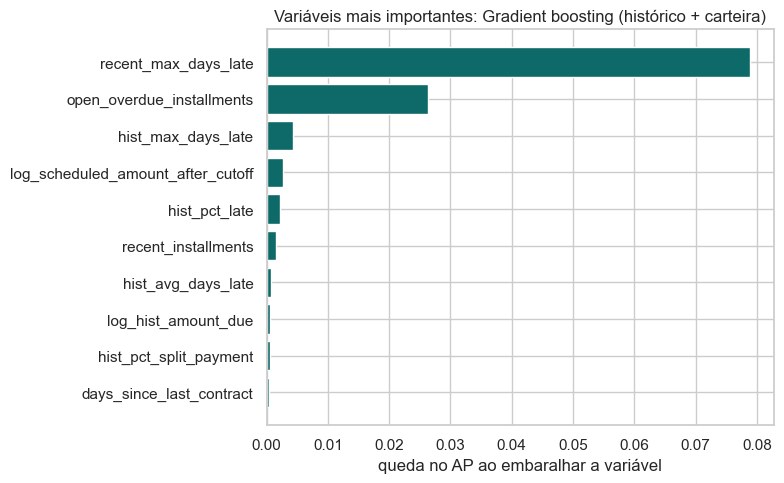

,queda no AP
variável,
recent_max_days_late,0.079
open_overdue_installments,0.026
hist_max_days_late,0.004
log_scheduled_amount_after_cutoff,0.003
hist_pct_late,0.002
recent_installments,0.001
hist_avg_days_late,0.001
log_hist_amount_due,0.001
hist_pct_split_payment,0.001


In [8]:
best_model = models[best_name]
best_features = model_features[best_name]
sample = X_test[best_features].sample(n=min(20_000, len(X_test)), random_state=SEED)
importance = permutation_importance(
    best_model, sample, y_test.loc[sample.index],
    scoring="average_precision", n_repeats=5, random_state=SEED,
)
importance_table = (
    pd.DataFrame({"variável": sample.columns, "queda no AP": importance.importances_mean})
    .sort_values("queda no AP", ascending=False)
    .set_index("variável")
)

top = importance_table.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top["queda no AP"], color="#0d6a68")
ax.set_xlabel("queda no AP ao embaralhar a variável")
ax.set_title(f"Variáveis mais importantes: {best_name}")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_importancia_variaveis.png", dpi=150)
plt.show()

importance_table

## 8. Análise de sensibilidade: critério de 30 dias

O mesmo modelo é treinado com o alvo de atraso acima de 30 dias, com a mesma divisão de treino e teste. Se as conclusões se mantiverem, a escolha de 15 dias não é o que sustenta o resultado.

In [9]:
y30 = df["target_late_30"].astype(int)
y30_train, y30_test = y30.loc[X_train.index], y30.loc[X_test.index]

model_30 = clone(best_model).fit(X_train, y30_train)
score_30 = model_30.predict_proba(X_test)[:, 1]

sens_rows = []
for label, y_eval, score in [("15 dias", y_test, test_scores[best_name]), ("30 dias", y30_test, score_30)]:
    cases_10, value_10 = capture_at_top(y_eval, score, value_test, 0.10)
    sens_rows.append({
        "critério": label,
        "taxa de risco": y_eval.mean(),
        "AUC": roc_auc_score(y_eval, score),
        "AP": average_precision_score(y_eval, score),
        "casos no top 10%": cases_10,
        "valor no top 10%": value_10,
    })
sens_table = pd.DataFrame(sens_rows).set_index("critério")
sens_table

,taxa de risco,AUC,AP,casos no top 10%,valor no top 10%
critério,,,,,
15 dias,0.017,0.738,0.118,0.447,0.462
30 dias,0.007,0.792,0.082,0.533,0.526


## 8.1. Quanto custa deixar o cadastro de fora?

O cadastro (renda, idade, emprego, tipo de renda, escolaridade e região) é do pedido atual, posterior à data de corte, e não é um critério justo para decidir como cobrar alguém. Por isso o modelo final usa só o comportamento (ver `docs/decisoes.md`, item 19).

Esta seção mede o preço dessa escolha: o modelo escolhido é treinado também com o cadastro e comparado com a versão só de comportamento. A comparação é feita por validação cruzada dentro do treino, como na seção 5, para que nenhuma escolha do projeto dependa do teste. As colunas de captura usam as previsões de cada cliente do treino feitas pelo modelo que não o viu.

In [10]:
model_with_profile = Pipeline([
    ("prep", make_preprocess(list(best_features) + PROFILE_NUMERIC, CATEGORICAL_FEATURES)),
    ("model", clone(best_model.named_steps["model"])),
])

profile_rows = []
for label, model in [("só comportamento (modelo final)", clone(best_model)),
                     ("comportamento + cadastro", model_with_profile)]:
    # AUC e AP: média das 5 partes, igual à tabela da seção 5
    cv_scores = cross_validate(model, X_train, y_train, cv=cv, scoring=["roc_auc", "average_precision"])
    # Captura no topo: previsão de cada cliente feita pelo modelo que não o viu no treino
    oof_score = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    cases_10, value_10 = capture_at_top(y_train, oof_score, value_train, 0.10)
    cases_20, _ = capture_at_top(y_train, oof_score, value_train, 0.20)
    profile_rows.append({"variáveis": label,
                         "AUC": cv_scores["test_roc_auc"].mean(),
                         "AP": cv_scores["test_average_precision"].mean(),
                         "casos no top 10%": cases_10, "valor no top 10%": value_10,
                         "casos no top 20%": cases_20})
profile_table = pd.DataFrame(profile_rows).set_index("variáveis")
profile_table

,AUC,AP,casos no top 10%,valor no top 10%,casos no top 20%
variáveis,,,,,
só comportamento (modelo final),0.766,0.134,0.474,0.492,0.599
comportamento + cadastro,0.773,0.136,0.477,0.494,0.596


## 9. Calibração das probabilidades

O peso de classe ajuda a ordenar, mas infla as probabilidades: o modelo passa a "achar" que o risco é maior do que realmente é. Para calcular o valor esperado em risco (probabilidade × valor a receber), a probabilidade precisa ser realista. A calibração isotônica ajusta os scores para que, num grupo de clientes com probabilidade de 5%, cerca de 5% de fato atrasem.

A tabela divide o teste em 10 grupos (decis) pelo score e compara a probabilidade média prevista com a taxa real de cada grupo.

In [11]:
calibrated = CalibratedClassifierCV(clone(best_model), method="isotonic", cv=cv)
calibrated.fit(X_train, y_train)
prob_test = calibrated.predict_proba(X_test)[:, 1]

calibration_table = (
    pd.DataFrame({"prob": prob_test, "real": y_test.to_numpy()})
    .assign(decil=lambda d: pd.qcut(d["prob"].rank(method="first", ascending=False), 10, labels=range(1, 11)))
    .groupby("decil", observed=True)
    .agg(clientes=("real", "size"), prob_media_prevista=("prob", "mean"), taxa_real=("real", "mean"))
)
print(f"Brier score sem calibração: {brier_score_loss(y_test, test_scores[best_name]):.4f}")
print(f"Brier score calibrado:      {brier_score_loss(y_test, prob_test):.4f}  (quanto menor, melhor)")
calibration_table

Brier score sem calibração: 0.1508
Brier score calibrado:      0.0155  (quanto menor, melhor)


,clientes,prob_media_prevista,taxa_real
decil,,,
1,4690,0.079,0.074
2,4690,0.021,0.023
3,4690,0.015,0.013
4,4690,0.012,0.013
5,4690,0.010,0.010
6,4690,0.008,0.008
7,4690,0.007,0.010
8,4690,0.006,0.007
9,4690,0.005,0.006


## 10. Scores de toda a carteira

Cada cliente recebe uma probabilidade calculada por um modelo que **não** o viu no treino (validação cruzada em 5 partes sobre a base inteira). Isso evita dar ao cliente um score otimista só porque ele estava no treino. Com a probabilidade, calcula-se o valor esperado em risco e o decil de risco (1 = os 10% de maior risco).

O resultado é gravado no SQL Server, em `analytics.client_scores`, para o Power BI. Esta etapa treina o modelo várias vezes e pode levar alguns minutos.

In [12]:
final_model = CalibratedClassifierCV(clone(best_model), method="isotonic", cv=5)
prob_all = cross_val_predict(final_model, X, y, cv=cv, method="predict_proba")[:, 1]

scores = pd.DataFrame({
    "client_id": df["client_id"],
    "risk_probability": prob_all.round(6),
    "expected_value_at_risk": (prob_all * value).round(2),
})
scores["risk_decile"] = pd.qcut(
    scores["risk_probability"].rank(method="first", ascending=False), 10, labels=range(1, 11)
).astype(int)

# O valor a receber já está em analytics.client_base; o Power BI liga as duas tabelas pelo client_id
write_table(scores, "client_scores", dtype={
    "client_id": Integer(),
    "risk_probability": Float(),
    "expected_value_at_risk": DECIMAL(18, 2),
    "risk_decile": SmallInteger(),
})

print(f"{len(scores):,} clientes gravados em analytics.client_scores")
print(f"Valor esperado em risco na carteira: {scores['expected_value_at_risk'].sum():,.0f}")
scores.groupby("risk_decile").agg(
    clientes=("client_id", "size"),
    prob_media=("risk_probability", "mean"),
    valor_esperado_em_risco=("expected_value_at_risk", "sum"),
)

156,333 clientes gravados em analytics.client_scores
Valor esperado em risco na carteira: 696,915,644


,clientes,prob_media,valor_esperado_em_risco
risk_decile,,,
1,15634,0.078,"317,727,345.990"
2,15633,0.020,"96,178,807.310"
3,15633,0.014,"56,282,190.810"
4,15633,0.012,"47,604,562.210"
5,15634,0.010,"44,515,779.840"
6,15633,0.009,"38,102,773.290"
7,15633,0.008,"33,720,886.010"
8,15633,0.007,"28,802,965.280"
9,15633,0.006,"21,987,890.950"


## 11. Resumo para a próxima etapa

In [13]:
# Sem arredondar antes de imprimir: o formato de exibição já usa 3 casas,
# e arredondar duas vezes pode mudar o último dígito
print(f"Modelo escolhido: {best_name}\n")
print("Validação cruzada (treino):")
print(cv_table.to_string(), "\n")
print("Teste:")
print(test_table.to_string(), "\n")
print("Sensibilidade:")
print(sens_table.to_string(), "\n")
print("Com e sem cadastro (validação cruzada no treino):")
print(profile_table.to_string(), "\n")
print("Variáveis mais importantes:")
print(importance_table.head(8).to_string(), "\n")
print("Calibração por decil (teste):")
print(calibration_table.to_string())

Modelo escolhido: Gradient boosting (histórico + carteira)

Validação cruzada (treino):
                                             AUC    AP
modelo                                                
Regressão logística (histórico)            0.755 0.110
Regressão logística (histórico + carteira) 0.764 0.124
Gradient boosting (histórico)              0.755 0.109
Gradient boosting (histórico + carteira)   0.766 0.134
Regra simples                              0.724 0.066 

Teste:
                                             AUC    AP  casos no top 10%  valor no top 10%  casos no top 20%  valor no top 20%
modelo                                                                                                                        
Regra simples                              0.714 0.062             0.385             0.369             0.539             0.562
Regressão logística (histórico)            0.737 0.093             0.433             0.399             0.556             0.541
Regressão 

## 12. Conclusões

**As variáveis de carteira no corte melhoram o modelo.** Na validação cruzada, a precisão média (AP) subiu de 0,110 para 0,124 na regressão logística e de 0,109 para 0,134 no gradient boosting quando, além do histórico de pagamento, entram as parcelas em aberto no corte, os contratos ativos e o saldo a vencer.

**Modelo escolhido: gradient boosting com histórico e carteira**, a combinação de maior AP na validação cruzada (0,134 contra 0,124 da regressão logística com as mesmas variáveis). A escolha seguiu a métrica principal definida antes de olhar o teste.

**Resultado no teste (clientes que o modelo não viu):**
- nos 10% de clientes com maior score estão 44,7% dos casos de risco e 46,2% do valor em risco, cerca de 4,5 vezes o que uma escolha aleatória alcançaria;
- a regra simples (ordenar pelo % de atraso recente) alcança 38,5% dos casos no top 10%;
- AP de 0,118, cerca de 7 vezes a taxa de risco da base (0,017).

No teste, a regressão logística com as mesmas variáveis ficou muito próxima (44,9% dos casos e 45,4% do valor no top 10%; AUC de 0,750 contra 0,738). As duas são boas opções; o gradient boosting foi mantido porque a escolha foi feita na validação cruzada, e trocar de modelo depois de ver o teste seria usar o teste para escolher.

**O que o modelo usa:** o maior atraso nos 6 meses antes do corte é o sinal mais forte (queda de 0,079 no AP ao embaralhar), seguido das parcelas vencidas e ainda em aberto no dia do corte (0,026), uma das variáveis de carteira. As demais têm efeito pequeno.

**Dados cadastrais:** ficaram fora do modelo porque são posteriores à data de corte e não são um critério justo para decidir como cobrar alguém (ver `docs/decisoes.md`, item 19). Na validação cruzada, incluí-los mudaria muito pouco (AUC de 0,773 contra 0,766; 47,7% contra 47,4% dos casos no top 10%; 49,4% contra 49,2% do valor).

**Robustez:** com o critério de 30 dias, o modelo alcança 53,3% dos casos no top 10% (AUC de 0,792). A conclusão não depende da escolha de 15 dias.

**Probabilidades calibradas:** em cada decil do teste, a probabilidade média prevista ficou próxima da taxa real (no decil de maior risco, 7,9% previsto contra 7,4% real). Isso permite multiplicar a probabilidade pelo valor previsto no corte para estimar o valor em risco.

**Valor esperado em risco na carteira:** 696,9 milhões, sobre 41,1 bilhões previstos para o período. É a base da régua de cobrança no notebook 03.

**Limitações:** o desempenho é moderado (AUC de 0,74 no teste), coerente com um modelo que usa só o histórico da própria empresa, sem dados de bureau de crédito. O modelo não foi testado em produção, e a base usa datas relativas a um novo pedido de crédito (ver `docs/decisoes.md`, item 16).
